# 5 · 用於生成與權力重新分配

壓縮只是手段,目的兩個:

1. **重建 vs 生成**:哪些方法能從潛空間**採樣造出新樣本**?(有 decoder 才行)
2. **權力重新分配**:每種 regime 把城市形態推向哪裡?——用潛空間位移量化「權力如何重寫城市」。

> 承接 NB4 的體制語料與潛空間。

## 環境 + 語料

In [1]:
import sys, os
from pathlib import Path
_here = Path(os.getcwd()).resolve()
_r07 = next((p for p in [_here, *_here.parents] if (p / 'nn').exists()), _here)
if str(_r07) not in sys.path: sys.path.insert(0, str(_r07))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import regime_latent as rl       # 體制形態層 + 中文字型
print('07 根:', _r07)
from regime_latent import encoders as L
df = pd.read_csv(rl._paths.CSV)
X = df[L.FEATURES].values.astype(float)
std = L.Standardizer().fit(X); Xz = std.transform(X)

07 根: C:\baidunetdiskdownload\power_to_form\DF26_ws18\07_Latent_Urban


## 5.1 採樣與生成能力
**能生成 = 有沒有 decoder。** t-SNE/Isomap 無逆映射→只能可視化;PCA/AE/VAE 能解碼。
指標:plausibility(生成點多像真實)、validity(守物理約束)、interp(插值連續)。

[fig] 06_gen_capability.png


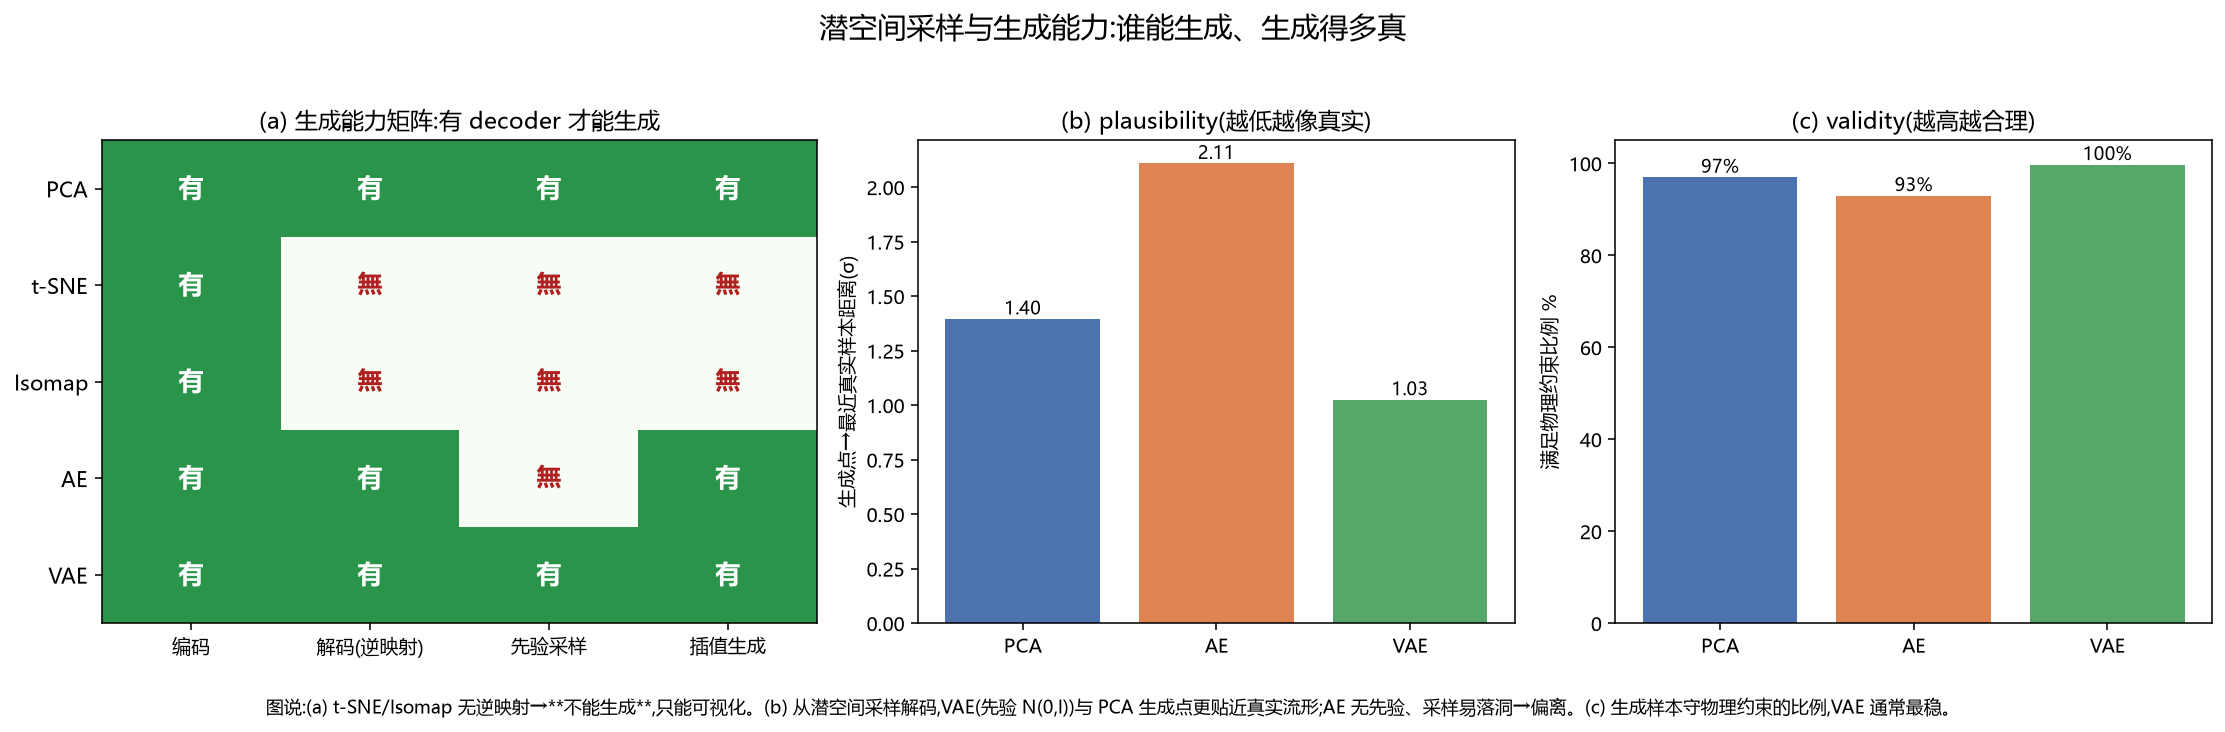

PCA  plaus=1.396 valid=97% interp=1.150
AE   plaus=2.109 valid=93% interp=1.426
VAE  plaus=1.025 valid=100% interp=1.042
t-SNE / Isomap:無 decoder,不可生成。


In [2]:
pca_ref, gen, gm = rl.generate.run(df, Xz, std)
rl.generate.fig_capability(gm)
display(Image(str(rl._paths.FIGS / '06_gen_capability.png')))
for g in ('PCA','AE','VAE'):
    m = gm[g]; print(f"{g:4s} plaus={m['plaus']:.3f} valid={m['valid']:.0f}% interp={m['interp']:.3f}")
print('t-SNE / Isomap:無 decoder,不可生成。')

## 5.2 真實 vs 生成點雲
生成雲應蓋住真實、不外溢也不塌成一點。VAE(先驗採樣)通常最貼。

[fig] 07_gen_cloud.png


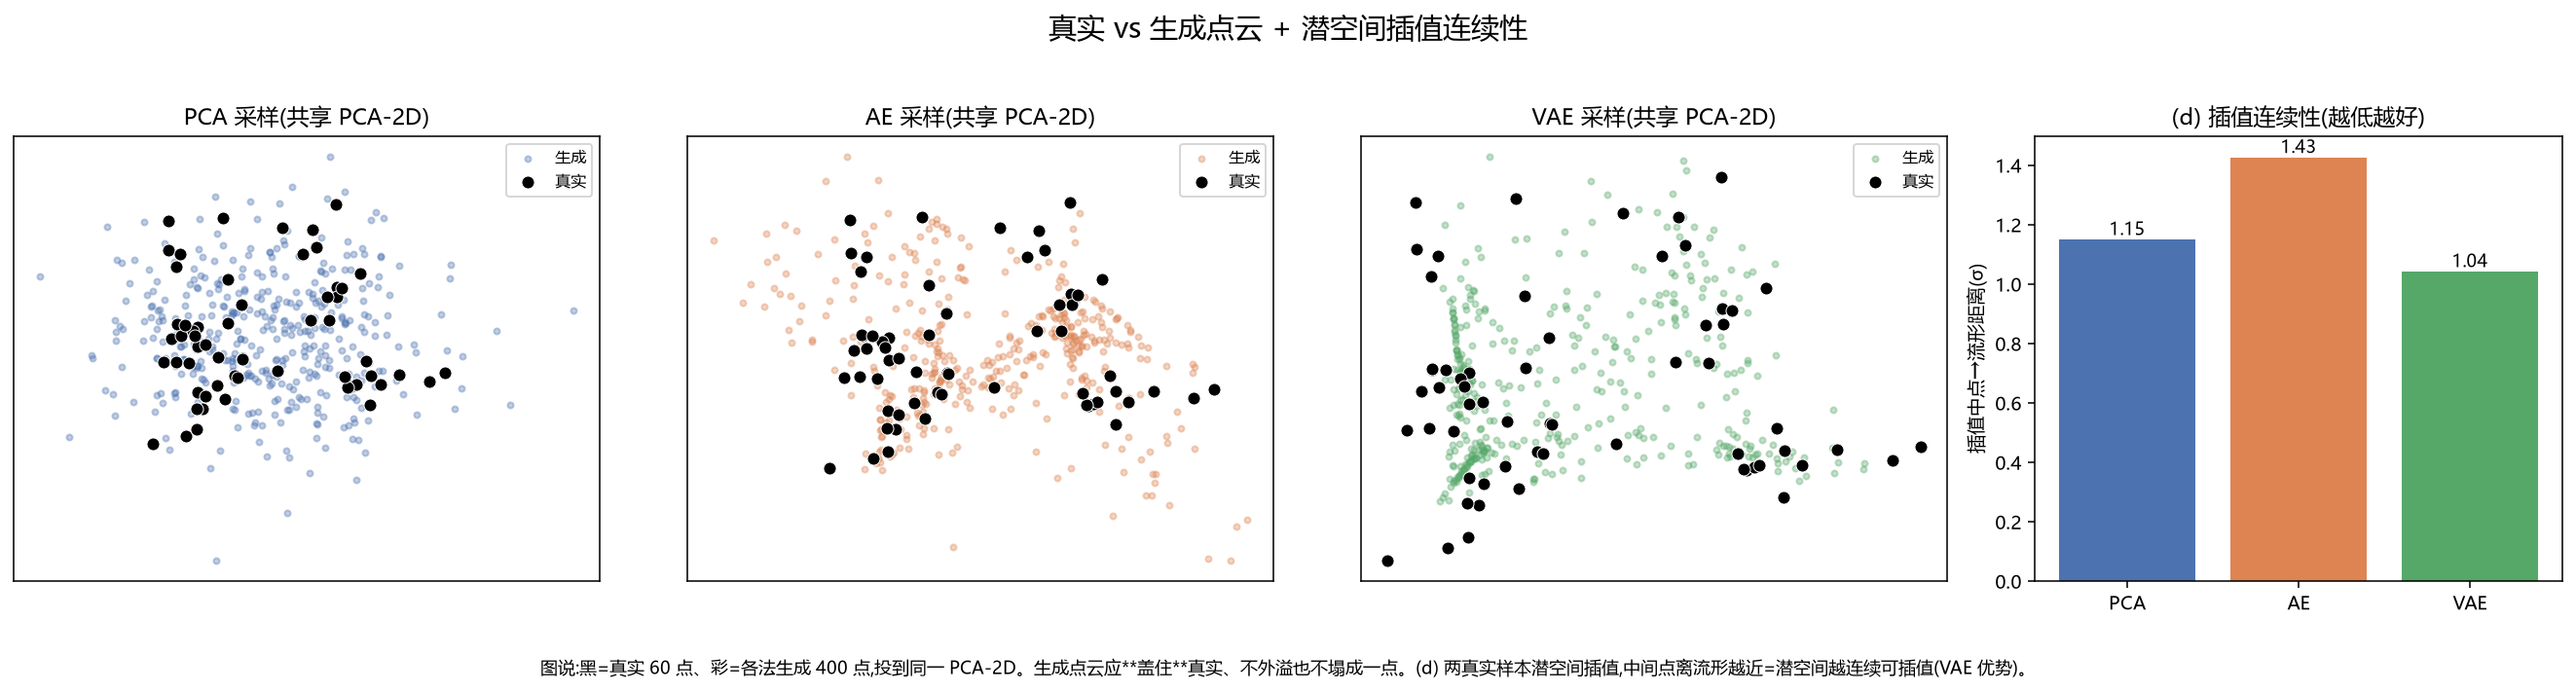

In [3]:
rl.generate.fig_cloud(pca_ref, Xz, gen, gm)
display(Image(str(rl._paths.FIGS / '07_gen_cloud.png')))

## 5.3 權力重新分配:體制的形態簽名
每 regime = baseline→體制的 Δ 特徵(σ,12 城均值)。這就是「權力重新分配」的量化:
開發商→拔高塔化、政府→向公共重心收攏、居民自建→細粒化、共享→釋放開放地面。

[fig] 04_cluster_interpret.png

=== silhouette ===
  space       按家族      按体制
  原始9维  0.037500 0.243968
   PCA -0.042284 0.236598
 t-SNE -0.029916 0.417653
Isomap -0.050955 0.273843
[fig] 05_regime_signature.png

=== 体制签名 Δ(σ,12城均值)===
        far  coverage  h_mean  h_max  h_cv  grain  slender  concentration     n
开发商主导  0.63     -0.43    1.22   0.27  0.37  -0.09     0.82          -0.03  0.03
政府主导  -0.13     -0.25    0.06  -0.46  0.70  -0.07    -0.12           1.82  0.00
居民自建  -1.47     -1.02   -1.06  -1.09 -1.20  -2.52     1.71          -0.01  2.16
共享    -0.99     -1.80    0.58  -1.70 -1.72  -0.65     1.86          -0.10  0.00


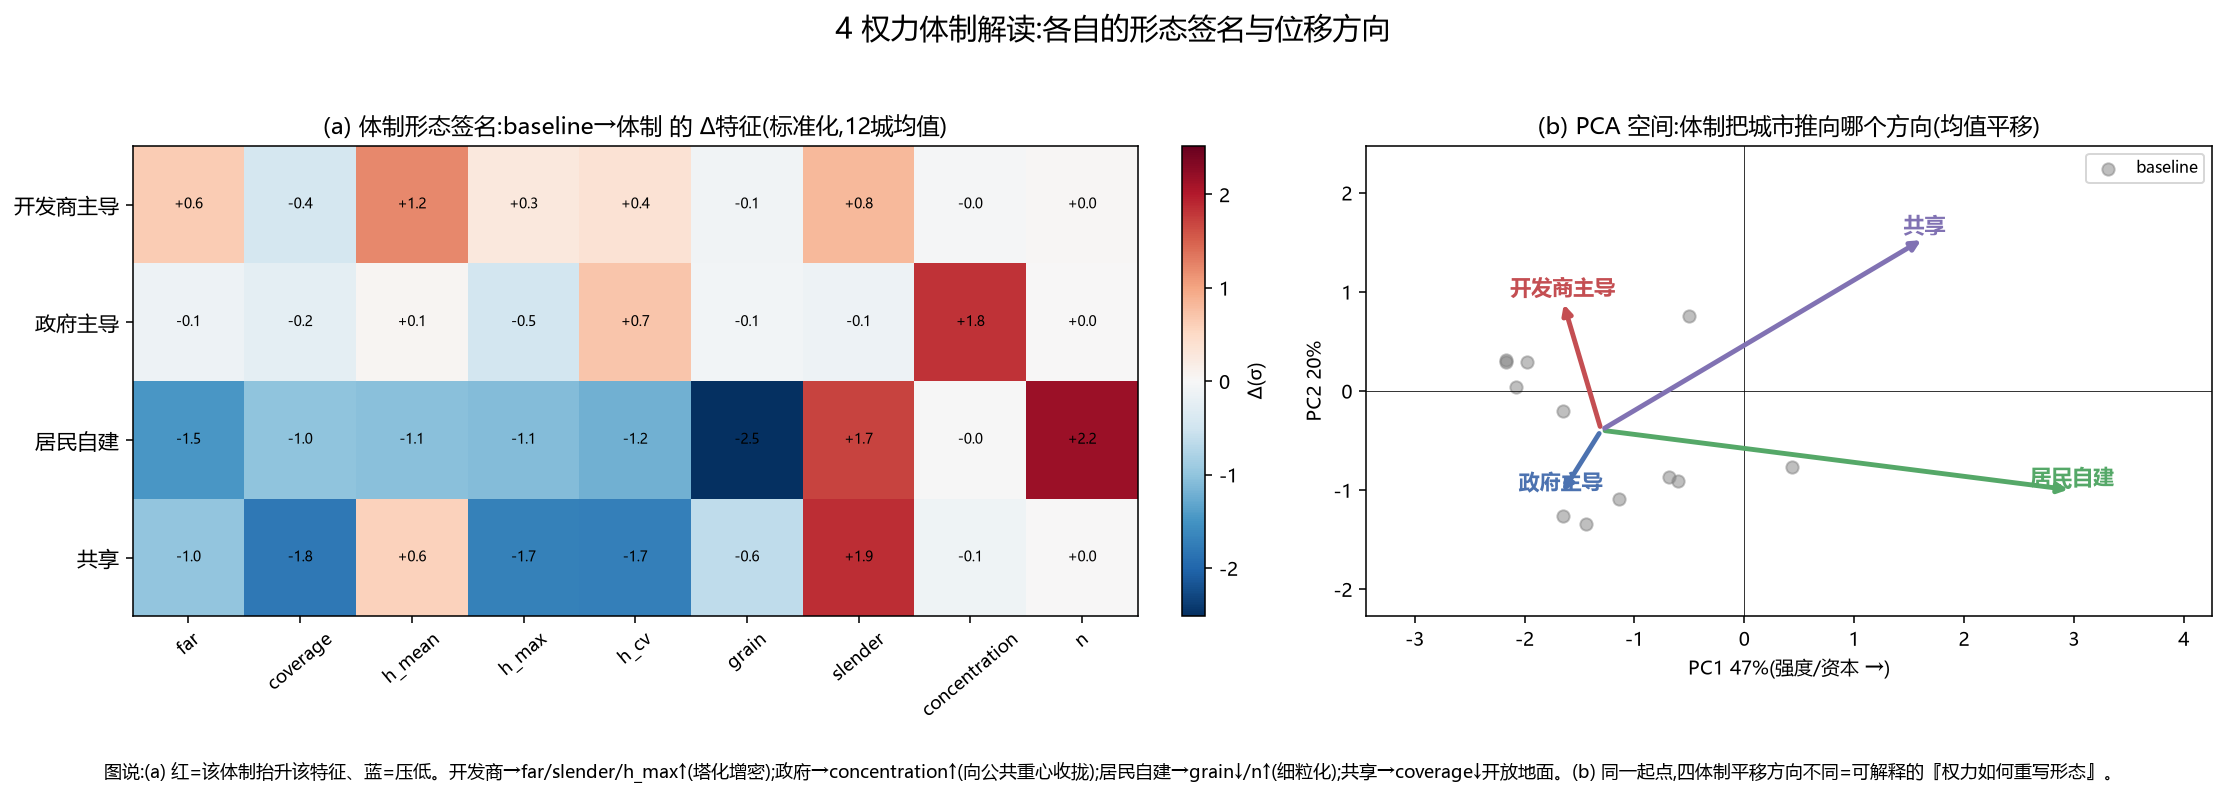

In [4]:
pca = rl.interpret.fig_cluster_interpret(df, Xz)   # 先取 PCA(供簽名圖)
rl.interpret.fig_regime_signature(df, Xz, std, pca)
display(Image(str(rl._paths.FIGS / '05_regime_signature.png')))

## 小結:給同學的啟發

| 目的 | 最佳方法 | 為什麼 |
|---|---|---|
| 壓縮/重建 | AE | 非線性瓶頸,重建誤差最低 |
| 採樣/生成 | **VAE** | 先驗 N(0,I),生成最真、插值最連續 |
| 可解釋軸 | PCA | 軸=特徵線性組合 |
| 空間紋理 | Conv-VAE | 卷積看街廓排列 |
| 只探索可視化 | t-SNE/Isomap | 分群清楚但不能生成 |

**NN 對 urban data 的啟發**:把城市形態壓進**連續、可採樣**的潛空間後,
「權力重新分配」不再只是手動規則,而能被**量化、比較、甚至生成**——這是深度學習
讓 05 資料能做更深分析的核心價值。